# Hit-Generation by Fragment-Based Molecular Optimization

In [1]:
#!pip install pyTDC msal

In [2]:
#!pip install safe-mol datamol pandas numpy rdkit msal 2>/dev/null | tail -n 1

In [3]:
from nv_genmol.optimizer import MolecularOptimizer
from nv_genmol.library import Library
from nv_genmol.genmol import GenMol_Generator
from nv_genmol.oracle import Oracle

import pandas as pd
import safe as sf

## Library & Seed

### Read molecular library of FDA-approved drugs with 20~30 heavy atoms 

In [4]:
mol_library = pd.read_csv('../../data/interim/genmol/BCS-CE65417_R1_testmulti.csv')
mol_library

,smiles,score
0,O=C(NCc1cccc(F)c1)C1CC([N+]Cl)=NO1,0.900
1,COC1=NOC(C(=O)NCc2cccc(I)c2)C1,0.835
2,O=C(Nc1[o+]cccc1O)C1CC(C(F)F)=NO1,0.808
3,COC(=O)c1ccc(C2=NOC(C(N)=O)C2)cc1,0.786
4,COCCC(=O)NC(=O)C1CC(C(C)C)=NO1,0.760
...,...,...
231,COC(=O)CCNNCCOc1cc(Cl)cc(Cl)c1,0.437
232,COC(=O)CCNOCCC(=O)Nc1cc(Cl)cc(Cl)c1,0.433
233,COC(=O)CCNOC[C@@H](O)COc1cc(Cl)cc(Cl)c1,0.406
234,COC(=O)CCN[N-]CC(=O)c1cc(Cl)cc(Cl)c1,0.364


### Seed

In [5]:
m1 = "CC1=NN(CC)C=C1CNC(=O)C1CC(=NO1)C1C=C(Br)C=CC=1"
m1_name = "BCS-CE65417"

## Create Oracle

In [11]:
# Test 2: With Multi-Objective.Oracle
from nv_genmol.by_genmol_oracle import MultiObjectiveOracle

#oracle_aih = MultiObjectiveOracle(
#    scoring_method="weighted_product",
#    logp_weight=1.0,
#    mw_weight=1.0,
#    qsar_weight=2.0,
#    use_qsar=True,
#    qsar_model="HSEC" # AIH or HSEC
#)

#V2 with tanimoto similarity to seed
test_m = "COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1"
oracle = MultiObjectiveOracle(
    scoring_method="enhanced",
    logp_weight=1.0,
    mw_weight=1.0,
    similarity_weight=1.0,
    use_similarity=True,
    reference_smiles=m1,
    qsar_weight=1.0,
    use_qsar=True,
    qsar_model="HSEC" # AIH or HSEC
)

In [12]:
# test eval with the original seed 
oracle.evaluate([test_m])

{'COC(=O)CCNC(=O)C1(C)CC(c2cc(Cl)cc(Cl)c2)=NO1': 0.7146007773532462}

In [13]:
oracle.debug_scoring(smiles=test_m)

{'score': 0.679486851849004,
 'properties': {'LogP': 2.5558000000000005,
  'MW': 359.209,
  'Similarity': 0.18823529411764706},
 'normalized': {'LogP': 0.5029000000000003,
  'MW': 0.501045,
  'Similarity': 0.18823529411764706},
 'desirability': {'LogP': 0.5029000000000003,
  'MW': 0.49895500000000004,
  'Similarity': 0.18823529411764706},
 'weights': {'LogP': 0.25, 'MW': 0.25, 'QSAR_HSEC': 0.25, 'Similarity': 0.25}}

### score the initial data with this new oracle

In [15]:
# re-score original data with oracle
results = oracle.evaluate(mol_library['smiles'])

In [16]:
# results to list
values_list = list(results.values())

# cross check
print(len(values_list))
print(len(mol_library))

#drop original score column
mol_library.drop('score',axis=1,inplace=True)

#create new score column with QSAR scores
mol_library['score'] = values_list
mol_library.sort_values(by='score',ascending=False, inplace=True)

#examples
mol_library.head()

236
236


,smiles,score
66,CCn1cc(CNC(=O)Cc2ccc(Br)cc2S)c(C)n1,0.784192
59,CCn1cc(CNC(=O)c2cc[nH]c2C(F)(F)F)c(C)n1,0.731806
58,CCn1cc(CNC(=O)N2CCC[C@H](CF)C2)c(C)n1,0.718067
0,O=C(NCc1cccc(F)c1)C1CC([N+]Cl)=NO1,0.707016
78,CCn1cc(CNC(=O)N[C@H](CCO)C(C)C)c(C)n1,0.686318


## Initiate fragment library from known molecules

In [17]:
library = Library(max_fragments = 1000)

In [18]:
molecules = {r['smiles']:r['score'] for idx, r in mol_library.iterrows()}
library.update(molecules)

In [19]:
#library.fragments
library.export(2)

['C17CC(CC(N)C4=O)=NO1.C18CC(C=O)=NO1.CC6CBr.C37=O.C58=O.N36.N45',
 'C1(=O)CC2.C3(CO)CI.CO1.N23']

## Generator

In [20]:
GENMOL_HOST = 'http://127.0.0.1:8083'
generator = GenMol_Generator(invoke_url = f"{GENMOL_HOST}/generate")

### Test generator

In [22]:
generator.produce(['CCC1CCC1CC(=O)NCCC(=O)OC'], 1)

['COc1cc(C(C)N)c(F)cc1Cl']

## Optimizer

In [24]:
optimizer = MolecularOptimizer(library = library, oracle = oracle, generator = generator)

In [25]:
data = []

In [26]:
steps=100

def eval():
    best = library.molecules.score[0]
    mean = library.molecules.head(50)['score'].mean()
    std = library.molecules.head(50)['score'].std()
    print(f"BEST {best:.4f} MEAN {mean:.4f} STD {std:.4f}")
    data.append([best, mean, std])

eval()

for i in range(steps):
    optimizer.run(iterations = 10, num_mutate = 50)
    print(f"Step: {i}")
    eval()

BEST 0.7841919749854305 MEAN 0.6084200598408935 STD 0.0464386143717111
Step: 0
BEST 0.7841919749854305 MEAN 0.6123016129316804 STD 0.047381771134213976
Step: 1
BEST 0.7841919749854305 MEAN 0.6134019381385362 STD 0.04672611730969555
Step: 2
BEST 0.7841919749854305 MEAN 0.6134019381385362 STD 0.04672611730969555
Step: 3
BEST 0.7841919749854305 MEAN 0.613450048627054 STD 0.04668370901487812
Step: 4
BEST 0.7841919749854305 MEAN 0.613450048627054 STD 0.04668370901487812
Step: 5
BEST 0.7841919749854305 MEAN 0.6142169621360551 STD 0.04630034864923428
Step: 6
BEST 0.7841919749854305 MEAN 0.6147247338643791 STD 0.04596938825866253
Step: 7
BEST 0.7841919749854305 MEAN 0.6173363606589587 STD 0.04727574173655399
Step: 8
BEST 0.7841919749854305 MEAN 0.6183246359043751 STD 0.04687212384225994
Step: 9
BEST 0.7841919749854305 MEAN 0.6183246359043751 STD 0.04687212384225994
Step: 10
BEST 0.7841919749854305 MEAN 0.6225180598613345 STD 0.04963116184258001
Step: 11
BEST 0.7841919749854305 MEAN 0.622518059

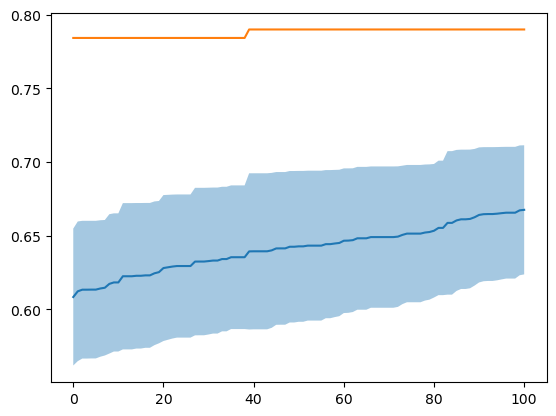

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(data, columns = ['best', 'mean', 'std'])

plt.fill_between(df.index, df['mean']-df['std'], df['mean'] + df['std'], alpha=0.4)
plt.plot(df['mean'])
plt.plot(df['best'])

In [28]:
df.shape

(101, 3)

# Outputs

In [29]:
df_safe = library.molecules
df_safe.head()

,smiles,score
0,CCn1cc(CNC2=NOC(OC(=O)NCc3cccc(F)c3)C2)c(C)n1,0.789940
1,CCn1cc(CNC(=O)Cc2ccc(Br)cc2S)c(C)n1,0.784192
2,CCn1cc(CNC2=NOC(OC(=O)NCc3cccc(Cl)c3)C2)c(C)n1,0.783773
3,CCn1cc(CNC(=O)c2cc(Cl)cc(Cl)c2)c(C)n1,0.751049
4,CCn1cc(CNC(=O)c2cc[nH]c2C(F)(F)F)c(C)n1,0.731806


In [30]:
len(df_safe)

446

CCn1cc(CNC(=O)Cc2ccc(Br)cc2S)c(C)n1


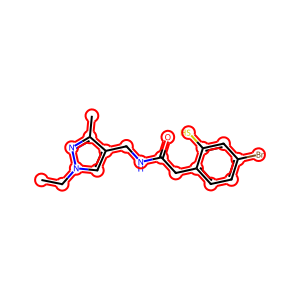

In [37]:
import safe as sf
print(df_safe.iloc[1,0])
sf.to_image(df_safe.iloc[1,0])


In [34]:
len(df_safe)

446

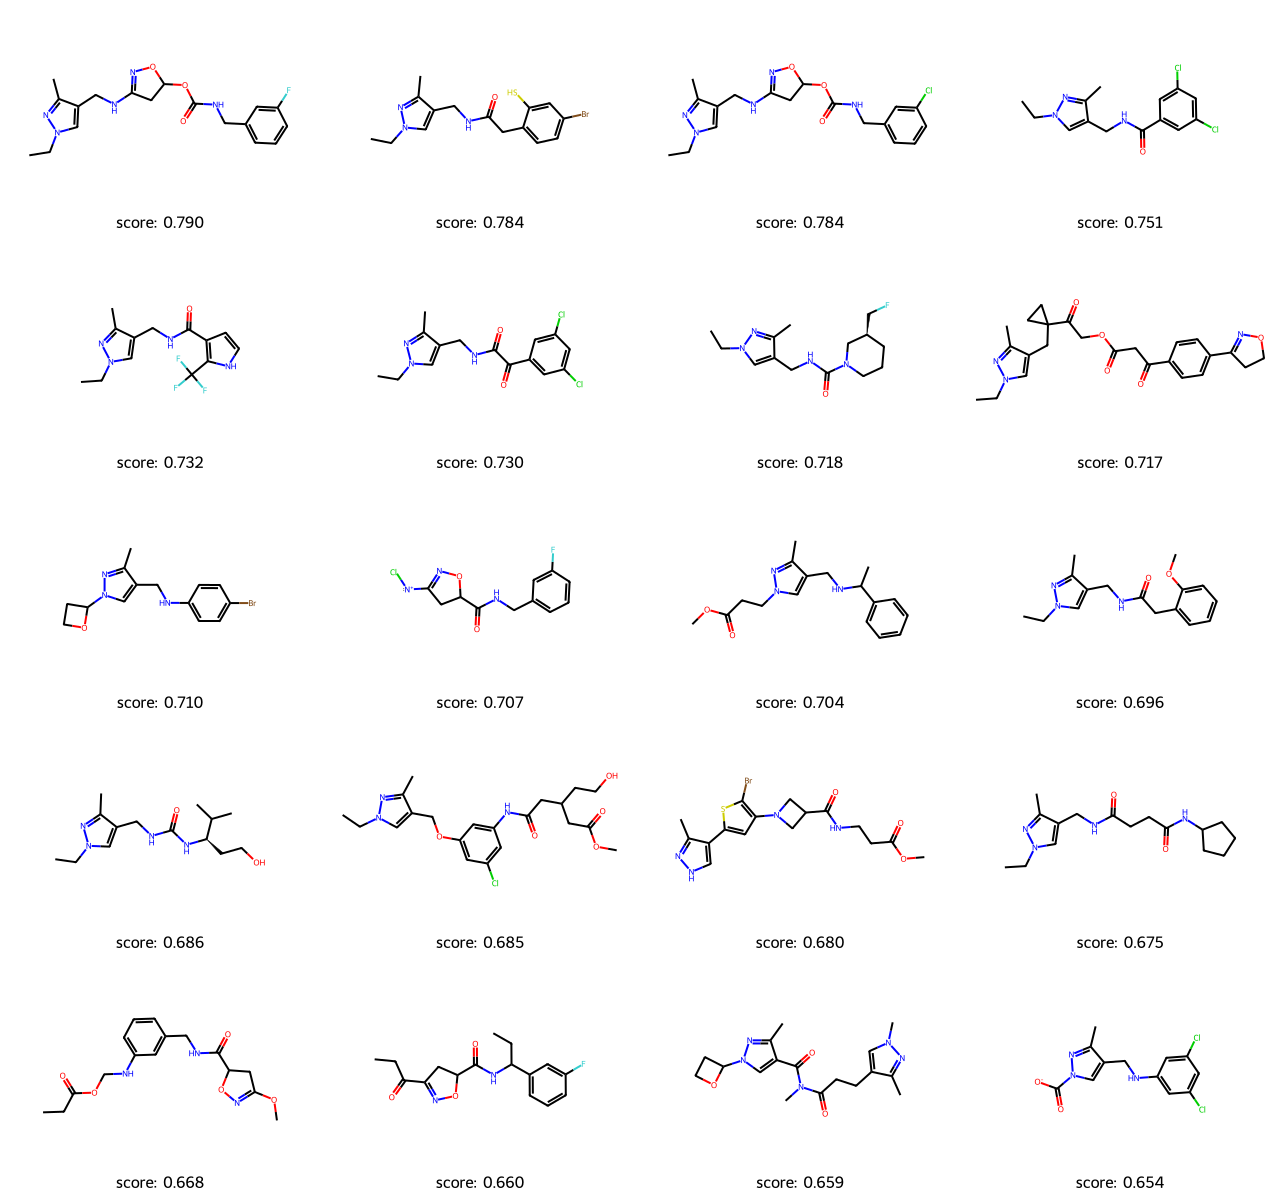

In [33]:
from rdkit.Chem import Draw
from rdkit import Chem
#select first 20
df_to_show = df_safe.iloc[0:20].copy()

#vis
ms = [Chem.MolFromSmiles(row['smiles']) for index, row in df_to_show.iterrows()]
legends = ['score: {:.3f}'.format(row['score']) for index, row in df_to_show.iterrows()]
#['score ' + str(row['score']) for index, row in df_to_show.iterrows()]
Draw.MolsToGridImage(ms, molsPerRow=4, subImgSize=(320, 240), legends=legends)


In [36]:
#df_safe.to_csv('../../data/processed/genmol/BCS-CE65417_moo-w-qsar.csv')